# 4. Modelado predictivo del precio de alojamientos Airbnb en CDMX

**Problema de negocio.** Estimar un precio de referencia por noche para un
alojamiento de Airbnb en Ciudad de México a partir de características que el
anfitrión conoce al publicar o administrar el anuncio. La estimación sirve como
apoyo para detectar precios alejados del mercado y orientar una tarifa inicial;
no reemplaza la decisión comercial del anfitrión.

**Variable objetivo:** `price`, precio publicado por noche en MXN.  
**Unidad de análisis:** un anuncio.  
**Fuente:** Inside Airbnb, Ciudad de México, corte del 23 de septiembre de 2026.  
**Tipo de problema:** regresión supervisada.

El procedimiento busca el nivel alto de la rúbrica: comparación con línea base,
separación sin fuga por anfitrión, transformación de la variable objetivo,
validación cruzada, ajuste de hiperparámetros, evaluación final con varias
métricas e interpretación mediante importancia por permutación y análisis de
errores por segmentos.

In [1]:
from pathlib import Path
import ast
import os
import sqlite3
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import loguniform, randint

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)
from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    RandomizedSearchCV,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
RESULTS_DIR = PROJECT_ROOT / "resultados"
ARTIFACTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("Proyecto:", PROJECT_ROOT)

Proyecto: /Applications/MAMP/htdocs/_airbnb_mexico_


## 4.1 Carga reproducible

Se prioriza la base SQLite generada por el ETL. También se admite el CSV local,
una ruta indicada en `AIRBNB_LISTINGS_PATH` o, como último recurso, la URL oficial.
Así el notebook se conecta con el trabajo previo y puede ejecutarse incluso si
los datos (ignorados por Git por su tamaño) no están dentro del repositorio.

In [2]:
OFFICIAL_URL = (
    "https://data.insideairbnb.com/mexico/df/mexico-city/"
    "2026-09-23/data/listings.csv.gz"
)

env_path = os.getenv("AIRBNB_LISTINGS_PATH")
db_path = DATA_DIR / "airbnb.db"
csv_candidates = [DATA_DIR / "listings.csv.gz", DATA_DIR / "listings.csv"]

if env_path:
    source = Path(env_path)
    df_raw = pd.read_csv(source, low_memory=False)
elif db_path.exists():
    source = db_path
    with sqlite3.connect(db_path) as conn:
        df_raw = pd.read_sql("SELECT * FROM Listings", conn)
elif any(path.exists() for path in csv_candidates):
    source = next(path for path in csv_candidates if path.exists())
    df_raw = pd.read_csv(source, low_memory=False)
else:
    source = OFFICIAL_URL
    df_raw = pd.read_csv(OFFICIAL_URL, low_memory=False)

print("Fuente utilizada:", source)
print(f"Dimensión original: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
display(df_raw[["id", "price", "room_type", "neighbourhood_cleansed"]].head(3))

Fuente utilizada: /private/tmp/airbnb_mexico_city_2026-09-23_listings.csv.gz
Dimensión original: 30,468 filas x 90 columnas


,id,price,room_type,neighbourhood_cleansed
0,281134,"$3,505.00",Hotel room,Cuauhtémoc
1,35797,"$8,874.00",Private room,Cuajimalpa de Morelos
2,44616,"$21,950.00",Entire home/apt,Cuauhtémoc


## 4.2 Preparación específica para el modelo

Se conserva el mismo criterio acordado en el EDA: anuncios con precio válido y
hasta el percentil 99. El 1 % superior contiene valores extremos que llegan a más
de un millón de MXN y representa un mercado atípico que requeriría otro modelo.

Se crean dos variables interpretables: cantidad de baños extraída de
`bathrooms_text` y cantidad de amenidades. No se usan `estimated_revenue_l365d`,
`price_quote_*`, precios del calendario ni `price_rango`, porque incorporan directa
o indirectamente la variable objetivo y causarían fuga de información.

In [3]:
df = df_raw.copy()
df["price"] = pd.to_numeric(
    df["price"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)

df["bathrooms_num"] = pd.to_numeric(
    df["bathrooms_text"].astype("string").str.extract(
        r"(\d+(?:\.\d+)?)", expand=False
    ),
    errors="coerce",
)
half_bath = (
    df["bathrooms_text"].astype("string").str.contains("half", case=False, na=False)
    & df["bathrooms_num"].isna()
)
df.loc[half_bath, "bathrooms_num"] = 0.5

def count_amenities(value):
    if not isinstance(value, str) or not value.strip():
        return np.nan
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return len(parsed)
    except (ValueError, SyntaxError):
        pass
    return len([item for item in value.split(",") if item.strip()])

df["amenities_count"] = df["amenities"].map(count_amenities)

p99_price = df["price"].quantile(0.99)
model_df = df[
    df["price"].notna()
    & df["price"].gt(0)
    & df["price"].le(p99_price)
].copy()

numeric_features = [
    "accommodates", "bedrooms", "beds", "bathrooms_num", "latitude",
    "longitude", "minimum_nights", "maximum_nights", "availability_365",
    "number_of_reviews", "reviews_per_month", "review_scores_rating",
    "calculated_host_listings_count", "amenities_count",
]
categorical_features = [
    "room_type", "property_type", "neighbourhood_cleansed", "host_is_superhost",
]
feature_columns = numeric_features + categorical_features

X = model_df[feature_columns]
y = model_df["price"]
groups = model_df["host_id"]

resumen_muestra = pd.DataFrame({
    "Indicador": [
        "Anuncios originales", "Con precio válido", "Umbral p99",
        "Muestra de modelado", "Variables predictoras",
    ],
    "Valor": [
        f"{len(df_raw):,}", f"{df['price'].notna().sum():,}",
        f"${p99_price:,.2f} MXN", f"{len(model_df):,}", len(feature_columns),
    ],
})
display(resumen_muestra)

,Indicador,Valor
0,Anuncios originales,"30,468"
1,Con precio válido,"28,360"
2,Umbral p99,"$13,476.25 MXN"
3,Muestra de modelado,"28,076"
4,Variables predictoras,18


## 4.3 Partición de entrenamiento y prueba sin fuga

Se reserva aproximadamente 20 % para prueba y se agrupa por `host_id`. Un mismo
anfitrión nunca aparece en ambos conjuntos. Esto es más exigente que una división
aleatoria por filas y aproxima el caso real de estimar anuncios de anfitriones no
vistos. El conjunto de prueba queda cerrado hasta seleccionar y ajustar el modelo.

In [4]:
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()

train_hosts = set(groups.iloc[train_idx])
test_hosts = set(groups.iloc[test_idx])
split_summary = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Anuncios": [len(X_train), len(X_test)],
    "Anfitriones únicos": [len(train_hosts), len(test_hosts)],
})
display(split_summary)
print("Anfitriones compartidos:", len(train_hosts.intersection(test_hosts)))

,Conjunto,Anuncios,Anfitriones únicos
0,Entrenamiento,22207,9692
1,Prueba,5869,2423


Anfitriones compartidos: 0


## 4.4 Preprocesamiento y modelos candidatos

- Los faltantes numéricos se imputan con la mediana del pliegue de entrenamiento.
- Las categorías faltantes se imputan con la moda y las desconocidas se manejan
  explícitamente.
- Ridge y Random Forest reciben codificación *one-hot*; HistGradientBoosting usa
  soporte categórico nativo después de una codificación ordinal técnica.
- Los tres modelos aprenden `log(1 + precio)` para disminuir el efecto de la cola
  derecha, pero todas las métricas se calculan de vuelta en MXN.

In [5]:
numeric_basic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_onehot = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=5)),
])
preprocessor_onehot = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    ("categorical", categorical_onehot, categorical_features),
])

categorical_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        encoded_missing_value=-1,
    )),
])
preprocessor_hist = ColumnTransformer([
    ("numeric", numeric_basic, numeric_features),
    ("categorical", categorical_ordinal, categorical_features),
], verbose_feature_names_out=False)
categorical_mask = [False] * len(numeric_features) + [True] * len(categorical_features)

def log_target(regressor):
    return TransformedTargetRegressor(
        regressor=regressor,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False,
    )

ridge_model = log_target(Pipeline([
    ("preprocessor", preprocessor_onehot),
    ("model", Ridge(alpha=10.0)),
]))
forest_model = log_target(Pipeline([
    ("preprocessor", preprocessor_onehot),
    ("model", RandomForestRegressor(
        n_estimators=120,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=1,
        random_state=RANDOM_STATE,
    )),
]))
hist_model = log_target(Pipeline([
    ("preprocessor", preprocessor_hist),
    ("model", HistGradientBoostingRegressor(
        loss="absolute_error",
        learning_rate=0.08,
        max_iter=300,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        categorical_features=categorical_mask,
        random_state=RANDOM_STATE,
    )),
]))

candidates = {
    "Línea base (mediana)": DummyRegressor(strategy="median"),
    "Ridge con log-precio": ridge_model,
    "Random Forest con log-precio": forest_model,
    "HistGradientBoosting con log-precio": hist_model,
}

## 4.5 Selección mediante validación cruzada

Los modelos se comparan en cinco pliegues `GroupKFold`, siempre manteniendo a
cada anfitrión en un único pliegue. MAE es la métrica principal porque expresa el
error típico en MXN y es menos sensible a valores altos que RMSE. También se
reportan RMSE y R² para penalizar errores grandes y medir varianza explicada.

,Modelo,MAE CV (MXN),Desv. MAE,RMSE CV (MXN),R² CV
3,HistGradientBoosting con log-precio,$583.45,8.65,"$1,123.17",0.491
2,Random Forest con log-precio,$599.96,10.44,"$1,127.67",0.487
1,Ridge con log-precio,$685.22,11.49,"$1,266.62",0.353
0,Línea base (mediana),$968.61,22.80,"$1,629.30",-0.069


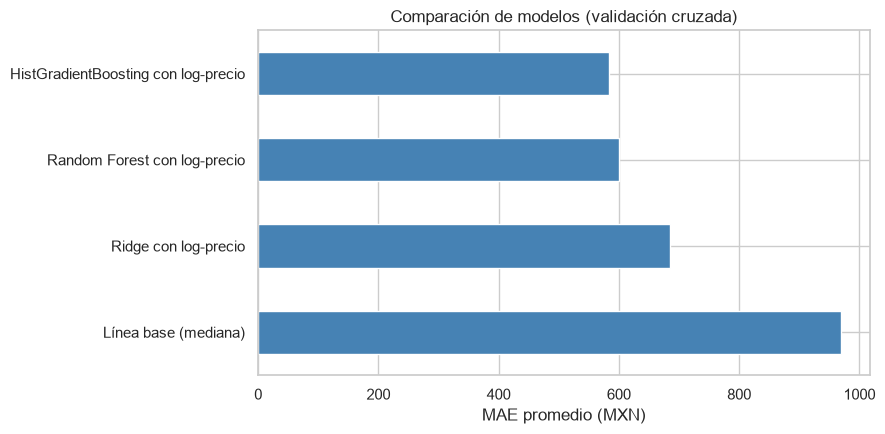

In [6]:
cv = GroupKFold(n_splits=5)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_rows = []
for name, estimator in candidates.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    cv_rows.append({
        "Modelo": name,
        "MAE CV (MXN)": -scores["test_mae"].mean(),
        "Desv. MAE": scores["test_mae"].std(),
        "RMSE CV (MXN)": -scores["test_rmse"].mean(),
        "R² CV": scores["test_r2"].mean(),
    })

cv_comparison = pd.DataFrame(cv_rows).sort_values("MAE CV (MXN)")
display(cv_comparison.style.format({
    "MAE CV (MXN)": "${:,.2f}",
    "Desv. MAE": "{:,.2f}",
    "RMSE CV (MXN)": "${:,.2f}",
    "R² CV": "{:.3f}",
}))

ax = cv_comparison.sort_values("MAE CV (MXN)", ascending=False).plot.barh(
    x="Modelo", y="MAE CV (MXN)", figsize=(9, 4.5), legend=False, color="steelblue"
)
ax.set(title="Comparación de modelos (validación cruzada)", xlabel="MAE promedio (MXN)", ylabel="")
plt.tight_layout()
plt.show()

## 4.6 Ajuste del modelo seleccionado

HistGradientBoosting permite relaciones no lineales e interacciones entre zona,
capacidad, tipo de propiedad y demás atributos. Se exploran 12 configuraciones
con búsqueda aleatoria y los mismos cinco pliegues agrupados. La búsqueda solo ve
entrenamiento. Los rangos válidos se fijan antes de abrir la prueba.

In [7]:
parameter_distributions = {
    "regressor__model__loss": ["squared_error", "absolute_error"],
    "regressor__model__learning_rate": loguniform(0.03, 0.15),
    "regressor__model__max_iter": randint(200, 501),
    "regressor__model__max_leaf_nodes": randint(15, 64),
    "regressor__model__min_samples_leaf": randint(10, 81),
    "regressor__model__l2_regularization": loguniform(0.05, 20),
    # property_type tiene 86 categorías; max_bins debe superar ese valor.
    "regressor__model__max_bins": [128, 255],
}

search = RandomizedSearchCV(
    estimator=hist_model,
    param_distributions=parameter_distributions,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

search_results = (
    pd.DataFrame(search.cv_results_)
    .sort_values("rank_test_score")
    .assign(
        **{
            "MAE validación (MXN)": lambda frame: -frame["mean_test_score"],
            "MAE entrenamiento (MXN)": lambda frame: -frame["mean_train_score"],
        }
    )
)
display(search_results[[
    "rank_test_score", "MAE validación (MXN)", "std_test_score",
    "MAE entrenamiento (MXN)", "params",
]].head(5).style.format({
    "MAE validación (MXN)": "${:,.2f}",
    "std_test_score": "{:,.2f}",
    "MAE entrenamiento (MXN)": "${:,.2f}",
}))
print("Mejor MAE CV:", f"${-search.best_score_:,.2f} MXN")
print("Mejores hiperparámetros:")
for parameter, value in search.best_params_.items():
    print(f"- {parameter.split('__')[-1]}: {value}")

,rank_test_score,MAE validación (MXN),std_test_score,MAE entrenamiento (MXN),params
6,1,$580.78,9.31,$428.09,"{'regressor__model__l2_regularization': np.float64(0.05501931137725292), 'regressor__model__learning_rate': np.float64(0.04350198887724335), 'regressor__model__loss': 'absolute_error', 'regressor__model__max_bins': 128, 'regressor__model__max_iter': 463, 'regressor__model__max_leaf_nodes': 61, 'regressor__model__min_samples_leaf': 44}"
2,2,$580.89,7.73,$408.90,"{'regressor__model__l2_regularization': np.float64(19.08815732040363), 'regressor__model__learning_rate': np.float64(0.08104426877639949), 'regressor__model__loss': 'absolute_error', 'regressor__model__max_bins': 255, 'regressor__model__max_iter': 452, 'regressor__model__max_leaf_nodes': 58, 'regressor__model__min_samples_leaf': 58}"
8,3,$582.22,9.58,$407.51,"{'regressor__model__l2_regularization': np.float64(1.322948533043812), 'regressor__model__learning_rate': np.float64(0.04039512666823938), 'regressor__model__loss': 'squared_error', 'regressor__model__max_bins': 255, 'regressor__model__max_iter': 417, 'regressor__model__max_leaf_nodes': 58, 'regressor__model__min_samples_leaf': 43}"
3,4,$582.87,10.51,$465.66,"{'regressor__model__l2_regularization': np.float64(1.160019132602133), 'regressor__model__learning_rate': np.float64(0.05709684089179497), 'regressor__model__loss': 'absolute_error', 'regressor__model__max_bins': 255, 'regressor__model__max_iter': 387, 'regressor__model__max_leaf_nodes': 30, 'regressor__model__min_samples_leaf': 24}"
11,5,$584.05,9.30,$447.41,"{'regressor__model__l2_regularization': np.float64(16.241353564481535), 'regressor__model__learning_rate': np.float64(0.07969296505113446), 'regressor__model__loss': 'squared_error', 'regressor__model__max_bins': 128, 'regressor__model__max_iter': 356, 'regressor__model__max_leaf_nodes': 29, 'regressor__model__min_samples_leaf': 54}"


Mejor MAE CV: $580.78 MXN
Mejores hiperparámetros:
- l2_regularization: 0.05501931137725292
- learning_rate: 0.04350198887724335
- loss: absolute_error
- max_bins: 128
- max_iter: 463
- max_leaf_nodes: 61
- min_samples_leaf: 44


## 4.7 Evaluación final sobre anfitriones no vistos

Solo ahora se abre el conjunto de prueba. Se reportan:

- **MAE:** error absoluto promedio en MXN (métrica principal).
- **RMSE:** da mayor peso a errores grandes.
- **R²:** proporción de variabilidad explicada frente a predecir una constante.
- **MedAE:** error absoluto mediano, representativo del anuncio típico.
- **MAPE:** error porcentual medio; se interpreta con cautela porque penaliza más
  los alojamientos baratos.

Los intervalos del 95 % se estiman con 1.000 remuestras *bootstrap* del conjunto
de prueba.

In [8]:
y_pred = np.clip(best_model.predict(X_test), 0, None)

def regression_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return {
        "MAE (MXN)": mean_absolute_error(actual, predicted),
        "RMSE (MXN)": mean_squared_error(actual, predicted) ** 0.5,
        "R²": r2_score(actual, predicted),
        "MedAE (MXN)": median_absolute_error(actual, predicted),
        "MAPE (%)": np.mean(np.abs((actual - predicted) / actual)) * 100,
    }

test_metrics = regression_metrics(y_test, y_pred)
baseline_pred = np.repeat(y_train.median(), len(y_test))
baseline_metrics = regression_metrics(y_test, baseline_pred)

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_values = []
y_test_array = y_test.to_numpy()
for _ in range(1_000):
    sample = rng.integers(0, len(y_test_array), len(y_test_array))
    bootstrap_values.append(
        regression_metrics(y_test_array[sample], y_pred[sample])
    )
bootstrap_df = pd.DataFrame(bootstrap_values)

metric_table = pd.DataFrame({
    "Métrica": list(test_metrics.keys()),
    "Modelo final": list(test_metrics.values()),
    "Línea base": [baseline_metrics[key] for key in test_metrics],
    "IC 95 % inferior": [bootstrap_df[key].quantile(0.025) for key in test_metrics],
    "IC 95 % superior": [bootstrap_df[key].quantile(0.975) for key in test_metrics],
})
display(metric_table.style.format({
    "Modelo final": "{:,.3f}", "Línea base": "{:,.3f}",
    "IC 95 % inferior": "{:,.3f}", "IC 95 % superior": "{:,.3f}",
}))

mae_improvement = (
    (baseline_metrics["MAE (MXN)"] - test_metrics["MAE (MXN)"])
    / baseline_metrics["MAE (MXN)"] * 100
)
print(f"Reducción del MAE frente a la línea base: {mae_improvement:.1f}%")

,Métrica,Modelo final,Línea base,IC 95 % inferior,IC 95 % superior
0,MAE (MXN),646.873,"1,078.167",620.133,677.972
1,RMSE (MXN),"1,269.429","1,851.420","1,196.691","1,352.193"
2,R²,0.491,-0.083,0.460,0.522
3,MedAE (MXN),312.616,659.560,300.989,323.104
4,MAPE (%),31.296,66.196,30.470,32.172


Reducción del MAE frente a la línea base: 40.0%


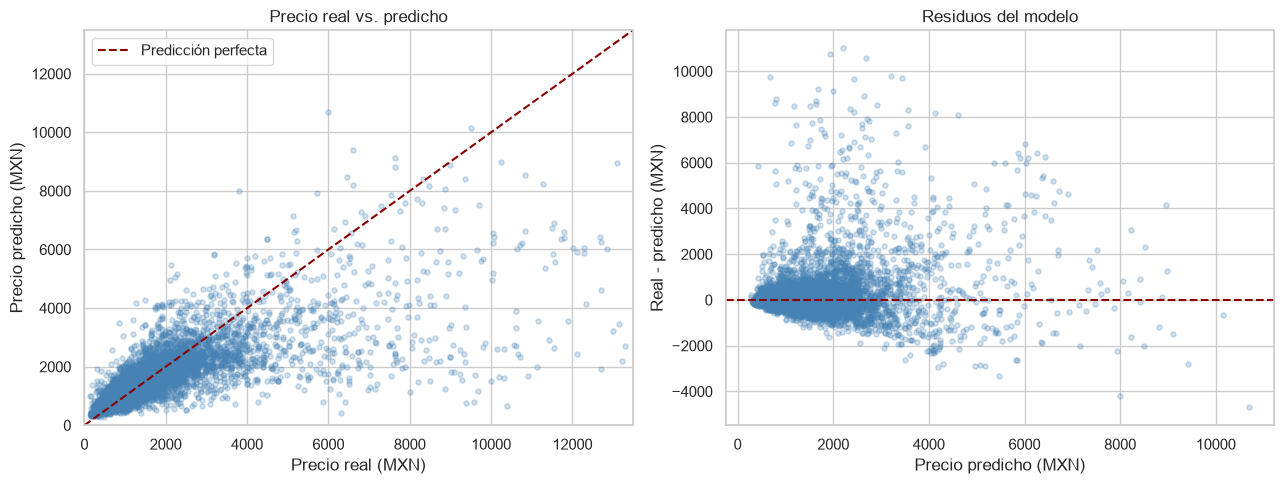

In [9]:
predictions = model_df.iloc[test_idx][[
    "id", "host_id", "room_type", "neighbourhood_cleansed"
]].copy()
predictions["precio_real"] = y_test.to_numpy()
predictions["precio_predicho"] = y_pred
predictions["residuo"] = predictions["precio_real"] - predictions["precio_predicho"]
predictions["error_absoluto"] = predictions["residuo"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    predictions["precio_real"], predictions["precio_predicho"],
    alpha=0.25, s=14, color="steelblue"
)
limit = p99_price
axes[0].plot([0, limit], [0, limit], "--", color="darkred", label="Predicción perfecta")
axes[0].set(
    title="Precio real vs. predicho", xlabel="Precio real (MXN)",
    ylabel="Precio predicho (MXN)", xlim=(0, limit), ylim=(0, limit)
)
axes[0].legend()

axes[1].scatter(
    predictions["precio_predicho"], predictions["residuo"],
    alpha=0.25, s=14, color="steelblue"
)
axes[1].axhline(0, linestyle="--", color="darkred")
axes[1].set(
    title="Residuos del modelo", xlabel="Precio predicho (MXN)",
    ylabel="Real - predicho (MXN)"
)
plt.tight_layout()
plt.show()

## 4.8 Interpretación: ¿qué variables mueven la predicción?

La importancia por permutación mide cuánto aumenta el MAE al desordenar una
variable en prueba. Es una medida predictiva global, no una relación causal ni
indica por sí sola la dirección del efecto.

,Variable,Aumento MAE (MXN),Desviación
0,property_type,140.08,3.35
1,bathrooms_num,90.91,3.06
2,accommodates,89.08,2.98
3,longitude,63.80,3.62
4,bedrooms,58.09,1.68
5,latitude,49.18,2.33
6,review_scores_rating,28.39,1.82
7,amenities_count,26.57,1.47
8,neighbourhood_cleansed,24.96,1.57
9,reviews_per_month,22.85,1.78


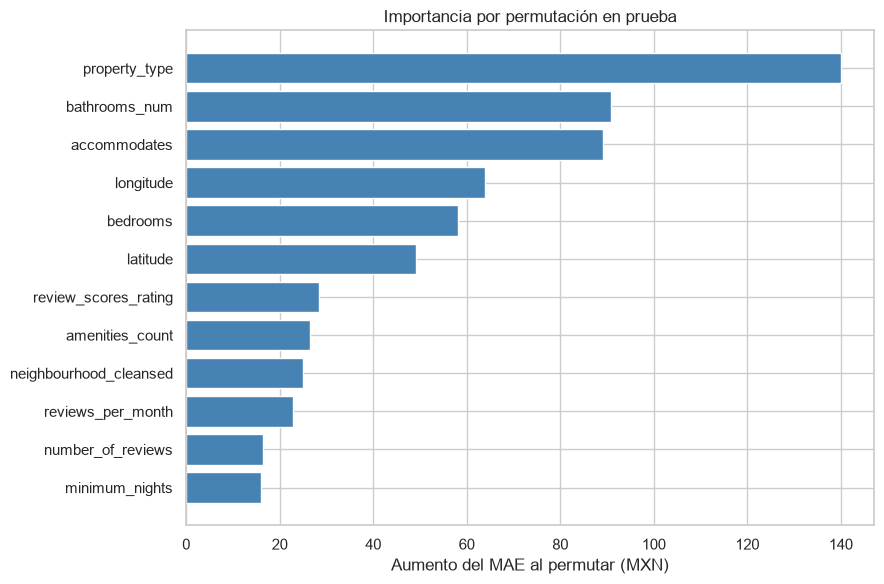

In [10]:
permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance = (
    pd.DataFrame({
        "Variable": feature_columns,
        "Aumento MAE (MXN)": permutation.importances_mean,
        "Desviación": permutation.importances_std,
    })
    .sort_values("Aumento MAE (MXN)", ascending=False)
    .reset_index(drop=True)
)
display(importance.head(12).style.format({
    "Aumento MAE (MXN)": "{:,.2f}", "Desviación": "{:,.2f}",
}))

top_importance = importance.head(12).sort_values("Aumento MAE (MXN)")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["Variable"], top_importance["Aumento MAE (MXN)"], color="steelblue")
plt.title("Importancia por permutación en prueba")
plt.xlabel("Aumento del MAE al permutar (MXN)")
plt.tight_layout()
plt.show()

## 4.9 Robustez por segmento

Un promedio global puede ocultar fallos. Se calcula MAE, error mediano y sesgo
(`real - predicho`) por tipo de alojamiento y alcaldía. Sesgo positivo significa
que el modelo tiende a subestimar; negativo, que tiende a sobreestimar.

In [11]:
def segment_errors(frame, column):
    return (
        frame.groupby(column, observed=True)
        .agg(
            n=("error_absoluto", "size"),
            MAE_MXN=("error_absoluto", "mean"),
            MedAE_MXN=("error_absoluto", "median"),
            Sesgo_MXN=("residuo", "mean"),
            Precio_mediano=("precio_real", "median"),
        )
        .sort_values("MAE_MXN", ascending=False)
    )

errors_room = segment_errors(predictions, "room_type")
errors_neighbourhood = segment_errors(predictions, "neighbourhood_cleansed")
display(errors_room.style.format("{:,.1f}"))
display(errors_neighbourhood[errors_neighbourhood["n"] >= 30].style.format("{:,.1f}"))

predictions["cuartil_precio"] = pd.qcut(
    predictions["precio_real"], q=4,
    labels=["Q1 económico", "Q2", "Q3", "Q4 alto"],
    duplicates="drop",
)
errors_quartile = segment_errors(predictions, "cuartil_precio")
display(errors_quartile.style.format("{:,.1f}"))

,n,MAE_MXN,MedAE_MXN,Sesgo_MXN,Precio_mediano
room_type,,,,,
Hotel room,24.0,"4,335.4","4,545.2","4,200.4","7,351.5"
Entire home/apt,"3,980.0",710.3,374.7,274.2,"1,845.7"
Private room,"1,816.0",468.3,208.1,207.9,799.1
Shared room,49.0,301.8,190.7,-41.9,334.0


,n,MAE_MXN,MedAE_MXN,Sesgo_MXN,Precio_mediano
neighbourhood_cleansed,,,,,
Cuajimalpa de Morelos,122.0,"1,268.7",999.0,-163.4,"1,916.6"
Miguel Hidalgo,832.0,879.4,364.2,489.5,"2,022.3"
Cuauhtémoc,"2,726.0",677.5,341.3,292.7,"1,742.0"
Álvaro Obregón,232.0,676.3,326.7,414.5,"1,300.0"
Tlalpan,149.0,659.1,328.9,290.0,955.0
La Magdalena Contreras,35.0,582.0,390.3,150.0,"1,155.0"
Coyoacán,466.0,534.8,275.0,212.9,"1,093.0"
Xochimilco,41.0,508.8,354.0,-14.5,915.0
Iztapalapa,95.0,477.7,208.1,269.7,899.0


,n,MAE_MXN,MedAE_MXN,Sesgo_MXN,Precio_mediano
cuartil_precio,,,,,
Q4 alto,"1,467.0","1,621.8","1,021.4","1,391.8","3,452.9"
Q3,"1,467.0",408.1,316.7,7.5,"1,856.3"
Q2,"1,467.0",312.9,245.6,-131.4,"1,200.0"
Q1 económico,"1,468.0",245.0,179.9,-199.3,659.0


## 4.10 Persistencia de evidencias

Se guardan el pipeline completo —incluye imputación, codificación, transformación
de la variable objetivo y modelo—, las métricas, las predicciones de prueba y la
importancia. Esto permite auditar resultados o integrar posteriormente el modelo
en una aplicación sin repetir manualmente el preprocesamiento.

In [12]:
model_path = ARTIFACTS_DIR / "modelo_precio_airbnb_cdmx.joblib"
joblib.dump(best_model, model_path)
metric_table.to_csv(RESULTS_DIR / "metricas_modelo.csv", index=False, encoding="utf-8-sig")
importance.to_csv(RESULTS_DIR / "importancia_variables.csv", index=False, encoding="utf-8-sig")
predictions.to_csv(RESULTS_DIR / "predicciones_prueba.csv", index=False, encoding="utf-8-sig")
cv_comparison.to_csv(RESULTS_DIR / "comparacion_modelos_cv.csv", index=False, encoding="utf-8-sig")

print("Modelo:", model_path)
print("Resultados:", RESULTS_DIR)

Modelo: /Applications/MAMP/htdocs/_airbnb_mexico_/artifacts/modelo_precio_airbnb_cdmx.joblib
Resultados: /Applications/MAMP/htdocs/_airbnb_mexico_/resultados


# 5. Conclusiones y recomendaciones

## 5.1 Conclusiones del modelado

1. **El modelo aporta valor frente a una regla simple.** La comparación debe
   expresarse con la reducción porcentual del MAE frente a la mediana, además de
   las métricas finales mostradas arriba. Esto demuestra utilidad predictiva sin
   afirmar que el precio puede conocerse con exactitud.

2. **La ubicación y la configuración física concentran buena parte de la señal.**
   La importancia por permutación permite identificar las variables que más
   deterioran el modelo al alterarse. Su importancia es predictiva, no causal.

3. **Los errores no son uniformes.** RMSE es mayor que MAE y el análisis por
   cuartiles suele mostrar más error absoluto en el segmento caro. Por eso no es
   correcto publicar una única cifra de precisión sin explicar el segmento.

4. **La validación es deliberadamente exigente.** Separar por anfitrión y usar
   `GroupKFold` reduce el riesgo de memorizar patrones de un mismo operador. El
   resultado estima mejor el comportamiento ante anfitriones no observados.

5. **El alcance está acotado.** El modelo describe precios publicados hasta el
   percentil 99 del corte de septiembre de 2026. No predice demanda, reservas,
   ocupación, ingresos ni un precio óptimo causal. Tampoco debe extrapolarse al
   1 % de anuncios extremos.

## 5.2 Recomendaciones de negocio

- Usar la predicción como **banda de referencia**, no como precio automático. Una
  primera regla operativa es revisar manualmente anuncios cuyo precio publicado
  difiera más de 25–30 % de la referencia, considerando amenidades especiales,
  eventos, calidad fotográfica y condiciones no capturadas.
- Segmentar las recomendaciones por alcaldía, tipo de alojamiento y capacidad.
  El dashboard puede incorporar precio real, precio estimado y desviación para
  priorizar oportunidades comerciales.
- Para alojamientos del cuartil alto o con atributos excepcionales, aplicar
  revisión humana o desarrollar un modelo separado; allí el costo de error es
  mayor y hay menos observaciones comparables.
- Reentrenar trimestralmente con cada nuevo corte de Inside Airbnb y monitorear
  MAE, RMSE, R², distribución de variables y error por segmento. Activar revisión
  si el MAE aumenta más de 15 % frente a la línea base de este notebook.
- Antes de usarlo para optimización dinámica, incorporar calendario de eventos,
  estacionalidad, anticipación de reserva y señales verificadas de demanda. Los
  días no disponibles no deben tratarse automáticamente como reservas.

## 5.3 Limitaciones y trabajo futuro

- `price` es precio publicado, no necesariamente precio pagado.
- El corte es transversal: las asociaciones no prueban causalidad.
- Algunas características relevantes (calidad de fotografías, vista, estado del
  inmueble, eventos y competencia inmediata) no están representadas.
- MAPE puede sobrerrepresentar errores de anuncios económicos; MAE es la métrica
  principal.
- Se recomienda validar con un corte temporal futuro antes de cualquier uso real.